In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
class Value:
    def __init__(self, data, _children=(), _op = '', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        # these two attr are used for building graphs
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), _op='+')

        def _backward():
            # dx/dself = dx/dout * dout/dself = out.grad * 1.0
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance (other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), _op='*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other): # other * self
        return self * other

    def __neg__(self): # -self
        return self * -1

    def __sub__(self, other): # self -  other
        return self + (-other)

    def __rsub__(self, other): # other - self
        return other + (-self)

    def __radd__(self, other): # other + self
        return self + other
        
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporint int/float powers for now."
        out = Value(self.data ** other, (self, ), f'**{other}')

        def _backward():
            self.grad += (other * self.data ** (other-1)) * out.grad

        out._backward = _backward
        return out
    
    def __truediv__(self, other):
        return self * other ** -1

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


a = Value(-4.0, label='a')
b = Value(2.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label='e'
d = e + c; d.label='d'
f = Value(-2.0, label='f')
L = d * f; L.label='L'
L

Value(data=-4.0)

In [4]:
a = Value(2.0)
b = Value(4.0)

a / b # a * (b ** -1)
a- b

Value(data=-2.0)

In [5]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(
        format='svg',
        graph_attr={'rankdir': 'LR'} # LR --> left to right
    )

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(
            name = uid,
            label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad),
            shape='record'
        )
        if n._op:
            # if this value is a result of some operation, 
            # create an op node for it
            dot.node(
                name = uid + n._op,
                label = n._op
            )
            # and connecr this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [6]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.881375070195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

o = n.tanh(); o.label='o'

In [7]:
o.backward()

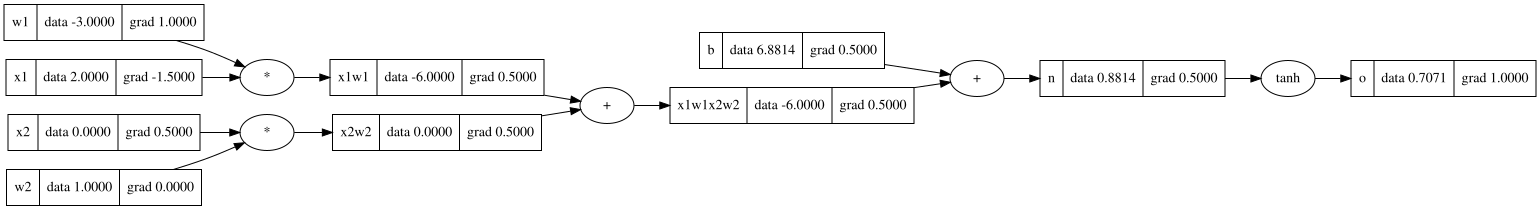

In [8]:
draw_dot(o)

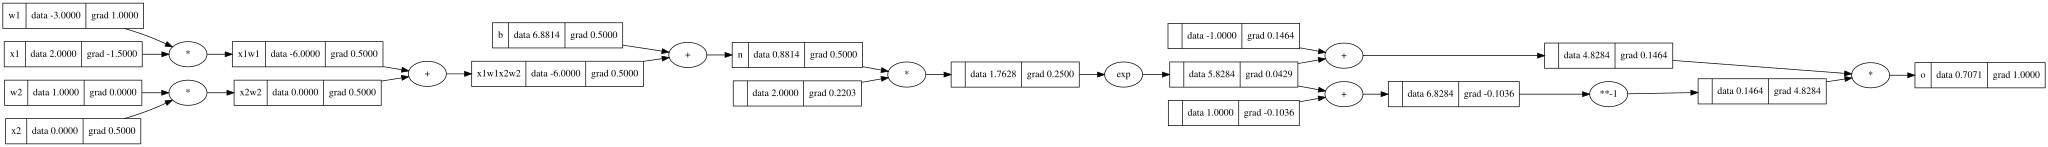

In [9]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.881375070195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

#-----
e = (2*n).exp()
o = (e - 1) / (e + 1)
#-----
o.label = 'o'
o.backward()
draw_dot(o)

In [10]:
import torch

In [11]:
x1 = torch.Tensor([2.0]).double()               ; x1.requires_grad = True
w1 = torch.Tensor([-3.0]).double()              ; w1.requires_grad = True
x2= torch.Tensor([1.0]).double()                ; x2.requires_grad = True
w2 = torch.Tensor([0.0]).double()               ; w2.requires_grad = True
b  = torch.Tensor([6.881375070195432]).double() ; b.requires_grad  = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("-------------")
print("x1 -->", x1.grad.item())
print("w1 -->", w1.grad.item())
print("x2 -->", x2.grad.item())
print("w2 -->", w2.grad.item())

0.7071074056602333
-------------
x1 --> -1.4999973505813626
w1 --> 0.9999982337209085
x2 --> 0.0
w2 --> 0.49999911686045423


In [12]:
import random

In [13]:
class Neuron:
    def __init__(self, nin): # nin --> no,of inputs
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        # w * x + b
        # __call__ --> n(x)
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b) # sum(wi*xi for wi, xi in zip(self.w, x)) + self.b
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        # nout --> no.of neurons in the layer / how many neurons we want in this layer
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons] # n.__call__(x)
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        params = []
        for neuron in self.neurons:
            ps = neuron.parameters()
            params.extend(ps)
        return params
class MLP:
    def __init__(self, nin, nouts):
        # nouts --> no.of neurons in all the layers it is a list
        """
        eg: nin = 2, nouts = [4, 4, 1]
        sz = [2, 4, 4, 1]
        2 --> input layer size, 4 --> 1st hidden layer
        4 --> 2nd hiddern layer, 1 --> output layer
        """
        sz = [nin] + nouts
        #layers = [Layer(2, 4), Layer(4, 4), Layer(4, 1)]
        #Layer(2, 4) = [Neuron(2), Neuron(2), Neuron(2), Neuron(2)]
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x) # layer.__call__(x)
        return x

    def parameters(self):
        params = []
        for layer in self.layers:
            ps = layer.parameters()
            params.extend(ps)
        return params
    


In [14]:
x = [2.0, 3.0, 4.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.08471706338052165)

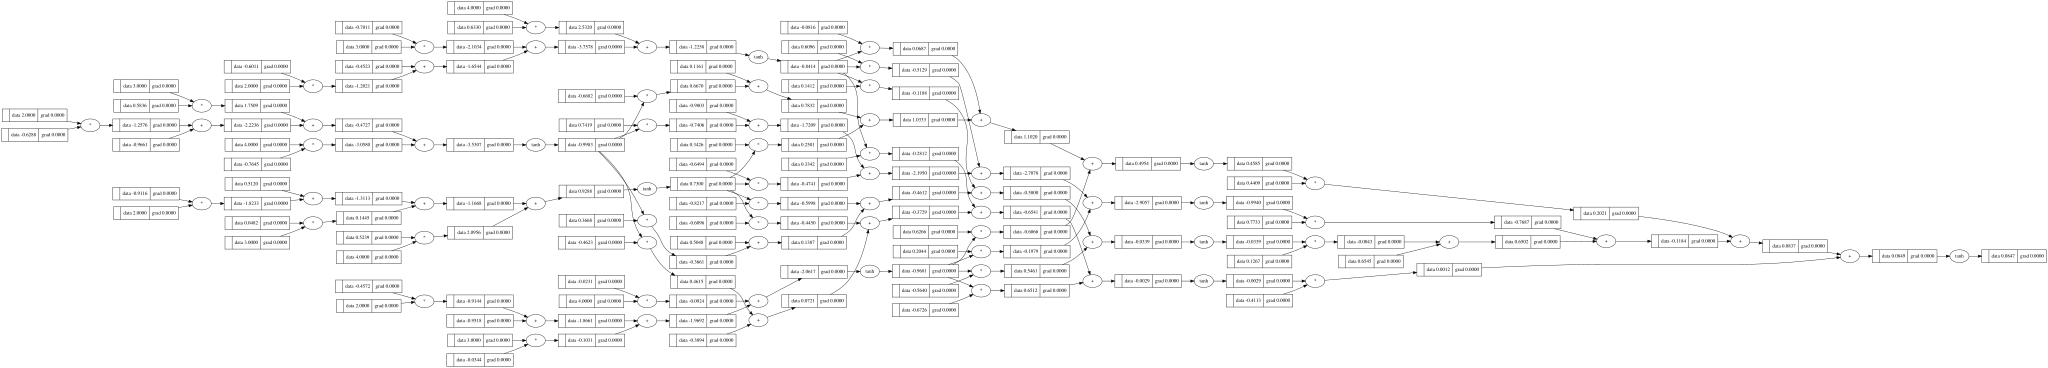

In [15]:
draw_dot(n(x))

In [16]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, 1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0] # desired targets

In [17]:
for k in range(20):
    # forward
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

    #backward
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    #update
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)

0 4.8221292803137175
1 3.169763632645247
2 2.0095559672115155
3 1.2120990573755652
4 0.7251552347781639
5 0.4687349621432622
6 0.3321043331205311
7 0.2521944800037752
8 0.20114746962036495
9 0.16620892158059447
10 0.14100271312478108
11 0.12206196573060601
12 0.10736422143526475
13 0.09565964191737189
14 0.0861383758535488
15 0.07825460491658114
16 0.07162808971000897
17 0.06598638300363072
18 0.06112949514581784
19 0.05690751117621399


In [18]:
ypred

[Value(data=0.9544588374267057),
 Value(data=-0.830879821788032),
 Value(data=-0.8917299124333451),
 Value(data=0.8795447504359074)]